# MAE · Stronger first reconstruction steps

**Experiment complete** · 2026-11-22T14:02:24+01:00

- matched · 4,500/4,500

At each archived +16 state, compare the archived action, one full-model 2× step, and one decoder-only 2× step. All scratch branches use 15 quarter-rate updates afterward. The authentic replay follows its archived actions. The primary measures are mean compensated current-frame MSE and delivered RankMe across the block.

## First look · Decoder-only 2× versus full 2×

Across arrivals 2–16, decoder-only changes mean compensated MSE by **-0.000451498** in the improvement direction with interval [-0.000600765, -0.000315694]. Delivered RankMe changes by **+0.0510106** with interval [+0.0433999, +0.0586749]. The 1,125 held-out origins begin at arrival 62,000. Paired intervals resample contiguous windows of 384 arrivals. All scores describe this seed and stream.

| Candidate | Reference | Mean MSE reduction | Paired 95% interval | Delivered RankMe change | Paired 95% interval | Native RankMe change | Both improved |
| --- | --- | --- | --- | --- | --- | --- | --- |
 | full 2x | existing +16 choice | +0.00233983 | [+0.00213203, +0.0025723] | -0.0292697 | [-0.0351364, -0.0239042] | -0.00152389 | 29.8% | 
 | decoder-only 2x | existing +16 choice | +0.00187474 | [+0.00172302, +0.00203602] | +0.0214748 | [+0.0174682, +0.0256767] | -0.000441313 | 63.4% | 
 | decoder-only 2x | full 2x | -0.000465091 | [-0.000607849, -0.000332478] | +0.0507445 | [+0.0430834, +0.058474] | +0.00108257 | 12.3% | 

## Does the first step pay off later?

| Contrast | Arrival 1 MSE reduction | Arrivals 2–16 MSE reduction | Arrival 17 pre-update MSE reduction |
| --- | --- | --- | --- |
 | full 2x vs. existing +16 choice | +0.00293459 | +0.00230018 | +0.00171971 | 
 | decoder-only 2x vs. existing +16 choice | +0.0022656 | +0.00184869 | +0.00138464 | 
 | decoder-only 2x vs. full 2x | -0.000668995 | -0.000451498 | -0.000335068 | 

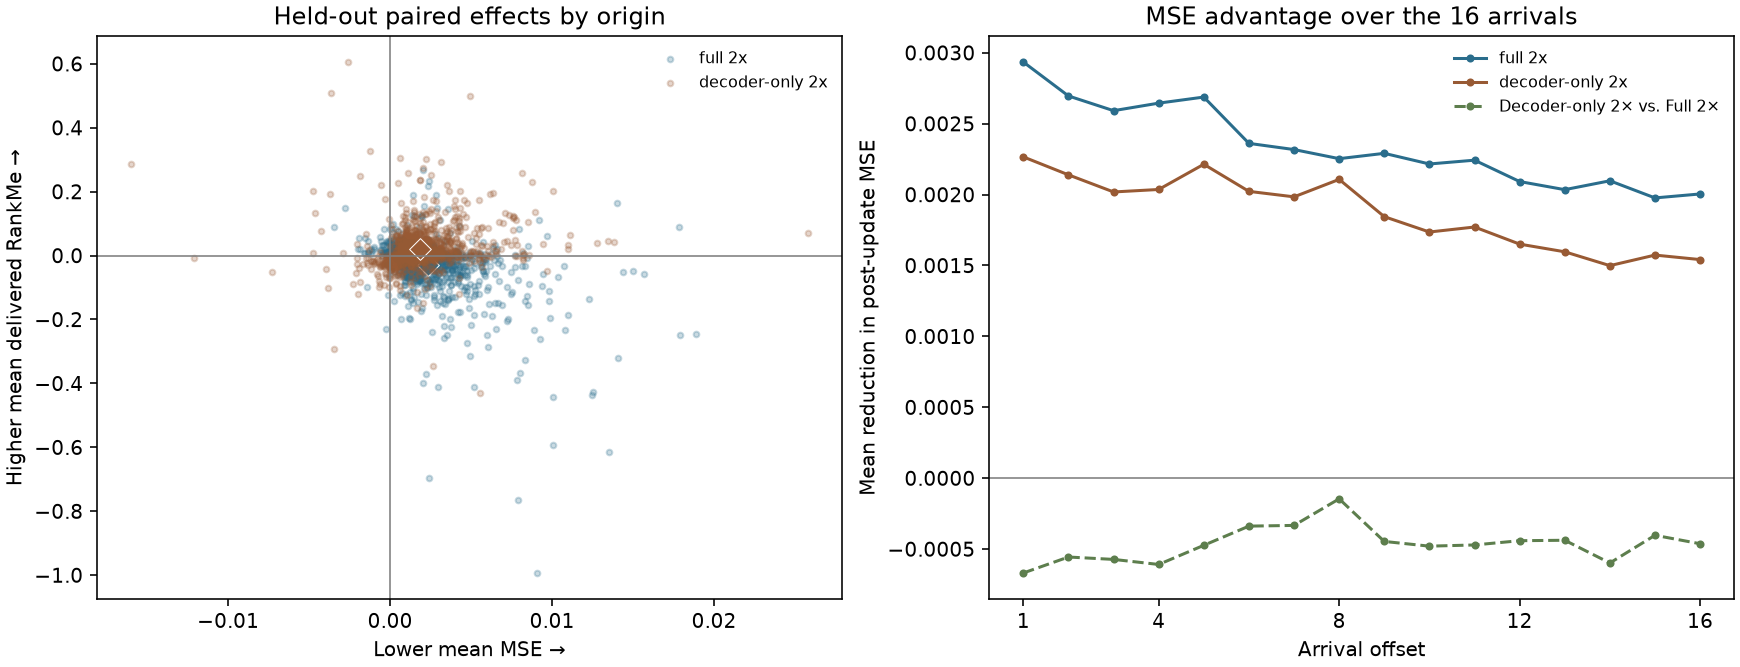

## O3 policy value on held-out blocks

| Policy | Compensated MSE | Delivered RankMe | Native RankMe | O3 utility | Choices by action |
| --- | --- | --- | --- | --- | --- |
 | existing +16 choice | 0.827948 | 13.47076 | 4.16043 | 7.202053 | [1125, 0, 0] | 
 | full 2x | 0.825608 | 13.44149 | 4.15890 | 7.189752 | [0, 1125, 0] | 
 | decoder-only 2x | 0.826074 | 13.49223 | 4.15999 | 7.233308 | [0, 0, 1125] | 
 | hindsight selector | 0.825923 | 13.50865 | 4.16056 | 7.249262 | [18, 380, 727] | 
 | causal ridge selector | 0.826160 | 13.49117 | 4.16023 | 7.231800 | [95, 120, 910] | 

Best held-out single action was **decoder-only 2x**. Hindsight added 0.0159543 O3 units over that action.

## Decision about live evaluation

Validation hindsight offered +0.00317668 MSE-equivalent gain. The best single validation action won 70.2% of origins. On independent validation mask repeats, winners agreed on 94.4% of origins. On held-out repeats, they agreed on 94.4%. Live advancement **none**.

Held-out predictor RMSE for MSE and delivered-RankMe advantages.

| Action | MSE RMSE | Delivered RankMe RMSE |
| --- | --- | --- |
 | full 2x | 0.00199277 | 0.0905886 | 
 | decoder-only 2x | 0.00204421 | 0.0676131 | 

The frozen selector gained -0.00150811 utility over the best held-out fixed action, with paired interval [-0.00359925, +0.000469239].